## Start or resume
After restarting the kernel, run the first code cell below. It restores all dependencies from saved preprocessing and the original CSV, without refitting or resaving. Then run the feature-extraction cell, or use Run All: preprocessing and split saving are automatically skipped when saved results exist. Keep REBUILD=False for normal use.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from sgcc_preprocessing import (
    stratified_split, fit_preprocessing, transform, load_saved_workflow,
)

# Leave False to reuse saved preprocessing. Set True only to rebuild it.
REBUILD = False
output_dir = Path("processed")
required_files = [output_dir / "sgcc_split.npz",
                  output_dir / "training_preprocessing.csv"]
loaded_saved = not REBUILD and all(path.exists() for path in required_files)
if loaded_saved:
    globals().update(load_saved_workflow())
    print(split_summary.to_string())
else:
    print("No complete saved preprocessing found, or REBUILD=True. Preparing from CSV.")


Loaded cleaned data and training statistics. Reading raw histories...
Ready: cleaned data, raw histories, labels, IDs and statistics restored.
       customers  theft_customers  theft_percent
train      33898             2892       8.531477
test        8474              723       8.531980


In [2]:
if not loaded_saved:
    df = pd.read_csv("data set.csv")
    label = df["FLAG"]
    X = df.drop(columns=["CONS_NO", "FLAG"])
    X.columns = pd.to_datetime(X.columns)
    X = X.sort_index(axis=1)
else:
    print("Using saved results; this step is skipped.")


Using saved results; this step is skipped.


In [3]:
print(df.shape, df["CONS_NO"].duplicated().sum(), label.value_counts(normalize=True))

(42372, 1036) 0 FLAG
0    0.914684
1    0.085316
Name: proportion, dtype: float64


## Split before preprocessing
Shuffle customers reproducibly (seed 42), stratifying on FLAG to preserve the observed ~8.53% theft share. Keep identifiers out of model features and keep dates in chronological order. Exploratory summaries below use training customers only.


In [4]:
if not loaded_saved:
    from sgcc_preprocessing import stratified_split, fit_preprocessing, transform
    
    assert df["CONS_NO"].notna().all() and df["CONS_NO"].is_unique
    train_idx, test_idx = stratified_split(label, test_fraction=0.2, seed=42)
    X_train_raw, X_test_raw = X.loc[train_idx].copy(), X.loc[test_idx].copy()
    y_train, y_test = label.loc[train_idx].copy(), label.loc[test_idx].copy()
    train_ids, test_ids = df.loc[train_idx, "CONS_NO"], df.loc[test_idx, "CONS_NO"]
    
    split_summary = pd.DataFrame({
        "customers": [len(y_train), len(y_test)],
        "theft_customers": [int(y_train.sum()), int(y_test.sum())],
        "theft_percent": [100 * y_train.mean(), 100 * y_test.mean()],
    }, index=["train", "test"])
    print(split_summary.to_string())
    assert set(train_ids).isdisjoint(set(test_ids))
    assert len(y_train) + len(y_test) == len(df)
    for labels in (y_train, y_test):
        assert abs(labels.mean() - label.mean()) <= 1 / len(labels)
else:
    print("Using saved results; this step is skipped.")


Using saved results; this step is skipped.


In [5]:
miss = X_train_raw.isna().mean(axis=1)           # per-customer missing ratio
print(miss.groupby(y_train).describe())   # compare thieves vs normal

zero_frac = (X_train_raw == 0).mean(axis=1)
mean_use = X_train_raw.mean(axis=1)
print(pd.DataFrame({"miss": miss, "zero": zero_frac, "mean": mean_use})
        .groupby(y_train).median())

        count      mean       std       min       25%       50%       75%  max
FLAG                                                                          
0     31006.0  0.250069  0.286725  0.000967  0.012573  0.091876  0.577369  1.0
1      2892.0  0.317918  0.292781  0.000967  0.023211  0.220986  0.705996  1.0
          miss      zero      mean
FLAG                              
0     0.091876  0.006770  5.418117
1     0.220986  0.002901  8.958485


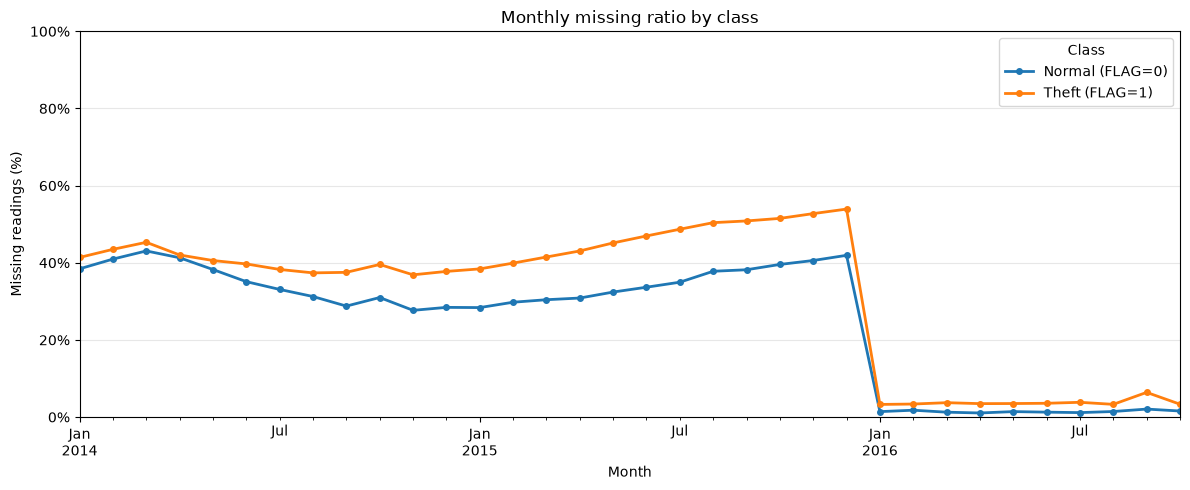

In [6]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Missing customer-day readings / available customer-day slots in each month.
# Zero consumption is observed data, not missing.
monthly_missing = (
    X_train_raw.isna().groupby(y_train).mean().T
    .resample("MS").mean()
)

ax = monthly_missing.rename(columns={0: "Normal (FLAG=0)", 1: "Theft (FLAG=1)"}).plot(
    figsize=(12, 5), marker="o", markersize=4, linewidth=2
)
ax.set(title="Monthly missing ratio by class", xlabel="Month",
       ylabel="Missing readings (%)", ylim=(0, 1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.legend(title="Class")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Fit on training customers; apply unchanged to test customers
Fill missing readings using each date's training median. Preserve observed zeros. Cap the upper tail (including the 800,003 reading) at each date's training 99.9th percentile, computed before imputation. This is a chosen preprocessing policy, not a threshold optimized on the test set; it can also cap legitimate high usage. Retain all customers, including those with entirely missing histories. Fallbacks for dates entirely missing in training also use training statistics only.


In [7]:
if not loaded_saved:
    preprocessing_stats = fit_preprocessing(X_train_raw)
    X_train = transform(X_train_raw, preprocessing_stats)
    X_test = transform(X_test_raw, preprocessing_stats)
    
    for name, raw, cleaned in (("train", X_train_raw, X_train), ("test", X_test_raw, X_test)):
        assert np.isfinite(cleaned.to_numpy()).all()
        assert (cleaned.le(preprocessing_stats["upper_cap"], axis=1)).all().all()
        assert cleaned.index.equals(raw.index) and cleaned.columns.equals(raw.columns)
        extreme = raw.ge(800003) & raw.lt(800004)
        print(f"{name}: missing={int(raw.isna().sum().sum()):,} -> {int(cleaned.isna().sum().sum())}; "
              f"max={raw.max().max():,.2f} -> {cleaned.max().max():,.2f}; "
              f"800,003 readings={int(extreme.sum().sum())}")
        if extreme.any().any():
            print("Replacement for 800,003:", cleaned.where(extreme).stack().to_dict())
else:
    print("Using saved results; this step is skipped.")


Using saved results; this step is skipped.


In [8]:
if not loaded_saved:
    from pathlib import Path
    
    output_dir = Path("processed")
    output_dir.mkdir(exist_ok=True)
    # Numeric arrays and string identifiers can be loaded with allow_pickle=False.
    np.savez_compressed(
        output_dir / "sgcc_split.npz",
        X_train=X_train.to_numpy(), X_test=X_test.to_numpy(),
        y_train=y_train.to_numpy(), y_test=y_test.to_numpy(),
        train_ids=train_ids.to_numpy(dtype=str), test_ids=test_ids.to_numpy(dtype=str),
        dates=X_train.columns.to_numpy(dtype="datetime64[ns]"),
        train_rows=train_idx, test_rows=test_idx,
    )
    preprocessing_stats.to_csv(output_dir / "training_preprocessing.csv", index_label="date")
    split_summary.to_csv(output_dir / "split_summary.csv", index_label="split")
    print("Saved processed/sgcc_split.npz and training preprocessing statistics.")
else:
    print("Using saved results; this step is skipped.")


Using saved results; this step is skipped.


## One feature row per customer
Consumption features (`mean`, `median`, population `std`, `max`, `cv=std/abs(mean)`, `peak_ratio=max/abs(mean)`, and `mean_abs_change`) use cleaned readings. Zero and missing features use raw readings, so imputation does not erase missingness or create observed zeros. Fractions use all daily slots; missing days interrupt zero runs. `miss_ratio_last90` uses the last 90 daily slots. `drop_ratio` is the fractional decrease in mean consumption from the preceding 90 days to the last 90 days, clipped to [0, 1]. Undefined ratios are zero. Short histories use available days; drop is zero without a preceding window.
Identifiers and labels are saved alongside features but excluded from model matrices. The existing customer split and training-only preprocessing are preserved.

Windows and runs count recorded date columns. The source omits 2016-09-18; no synthetic column is inserted.


In [9]:
from sgcc_preprocessing import extract_features

X_train_features = extract_features(X_train_raw, X_train)
X_test_features = extract_features(X_test_raw, X_test)

for name, features, ids, labels in (
    ("train", X_train_features, train_ids, y_train),
    ("test", X_test_features, test_ids, y_test),
):
    assert features.index.equals(labels.index)
    assert features.shape == (len(labels), 13)
    assert np.isfinite(features.to_numpy()).all()
    exported = pd.concat([ids.rename("CONS_NO"), labels.rename("FLAG"), features], axis=1)
    exported.to_csv(output_dir / f"{name}_features.csv", index=False)
    print(f"{name}: {features.shape[0]:,} customers x {features.shape[1]} features")

np.savez_compressed(
    output_dir / "sgcc_features.npz",
    X_train=X_train_features.to_numpy(), X_test=X_test_features.to_numpy(),
    y_train=y_train.to_numpy(), y_test=y_test.to_numpy(),
    train_ids=train_ids.to_numpy(dtype=str), test_ids=test_ids.to_numpy(dtype=str),
    feature_names=X_train_features.columns.to_numpy(dtype=str),
    train_rows=train_idx, test_rows=test_idx,
)
print(X_train_features.head().to_string())


train: 33,898 customers x 13 features
test: 8,474 customers x 13 features
            mean  median         std         max        cv  peak_ratio  zero_frac  longest_zero_run  miss_ratio  longest_nan_run  miss_ratio_last90  mean_abs_change  drop_ratio
34931   5.849313   4.460    5.659388   150.40000  0.967530   25.712420   0.005803                 1    0.482592              322           0.000000         1.510939    0.000000
20221  15.919339  13.420   66.418053  2141.38651  4.172161  134.514788   0.006770                 5    0.007737                4           0.000000         6.877709    0.162119
37285  68.725450   9.860  100.124296   353.66000  1.456874    5.145983   0.000000                 0    0.483559              253           0.000000         6.888161    0.000000
16043   7.237147   5.500    7.368520   150.40000  1.018153   20.781670   0.052224                27    0.004836                3           0.000000         2.547531    0.151500
25213   5.021625   3.745    7.365034   15

## Baselines: training-only selection, one holdout evaluation
Compare chance (the analytical theft-rate reference), `drop_ratio`, and `miss_ratio`, with larger scores always riskier. Select by training average precision before reading test features. PR-AUC means non-interpolated average precision; no classification threshold is tuned. A finite random ranking can fluctuate around the chance reference.

The first run saves the training decision, evaluates all three once, and writes a report. Later runs display saved results without rescoring. Strong missingness performance is a data-collection artifact warning given the January 2016 break, not evidence of theft behavior.

In [1]:
from pathlib import Path
from IPython.display import Markdown, display
from sgcc_baselines import run_baselines

baseline_dir = Path('processed')
if not (baseline_dir / 'baseline_results.csv').exists():
    run_baselines(baseline_dir)
display(Markdown((baseline_dir / 'baseline_report.md').read_text(encoding='utf-8')))


# Baseline benchmark

Rules and score directions were fixed in advance. The baseline with the highest training AP was selected and saved before loading test data. All three baselines were then evaluated in one holdout pass, without test-based selection or tuning. No threshold is needed for ranking AP.

Training-selected baseline: **missing_data**.

| Baseline | Train PR-AUC | Test PR-AUC | Test / chance |
| --- | ---: | ---: | ---: |
| chance | 0.085315 | 0.085320 | 1.00 |
| drop | 0.083576 | 0.084234 | 0.99 |
| missing_data | 0.109989 | 0.101003 | 1.18 |

PR-AUC here means non-interpolated average precision with tied scores grouped, not trapezoidal integration. Chance is the analytical prevalence reference, not a sampled random permutation: finite random rankings fluctuate around this reference.

Missingness-only AP is 0.101003, 1.18x chance (above the prevalence reference). This measures how well a pure data-collection artifact can rank theft labels. Given the January 2016 collection break, above-chance performance is an artifact warning, not evidence of theft behavior or proof that the break caused the association.

Drop uses the existing cleaned-history drop_ratio (last 90 versus preceding 90 recorded days); missingness uses raw-history miss_ratio. Preprocessing statistics were fitted on training customers only. These are fixed numbers for a model to beat; do not tune against test results.
